# API tour

The parts of the CtreeX API not covered by the other notebooks, using the [UCI German Credit][gc] data (see `02_german_credit.ipynb` for a description):

1. feature specifications from column names, decoding data points;
2. the explainer: class names, leaves, distances, the details of the counterfactuals;
3. legacy and fixed behaviour, individual fixes;
4. trees independent of scikit-learn;
5. leaf-to-leaf distances: bar plot and support sets;
6. the scikit-learn helpers.

[gc]: https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

In [1]:
import hashlib, os, urllib.request
import numpy as np

URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data'
SHA256 = 'b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc9715c7a86202cb5871'
PATH = 'german.data'
if not os.path.isfile(PATH):
    urllib.request.urlretrieve(URL, PATH)
with open(PATH, 'rb') as f:
    assert hashlib.sha256(f.read()).hexdigest() == SHA256, 'unexpected data file'
rows = [line.split() for line in open(PATH) if line.strip()]
len(rows), rows[0]

(1000,
 ['A11',
  '6',
  'A34',
  'A43',
  '1169',
  'A65',
  'A75',
  '4',
  'A93',
  'A101',
  '4',
  'A121',
  '67',
  'A143',
  'A152',
  '2',
  'A173',
  '1',
  'A192',
  'A201',
  '1'])

In [2]:
FEATURES = [
    ('checking_account', {'A11': '< 0 DM', 'A12': '0 to 200 DM', 'A13': '>= 200 DM', 'A14': 'no checking account'}),
    ('duration', None),
    ('credit_history', {'A30': 'no credits taken', 'A31': 'all credits at this bank paid back',
                        'A32': 'existing credits paid back so far', 'A33': 'delays in the past',
                        'A34': 'critical account'}),
    ('purpose', {'A40': 'new car', 'A41': 'used car', 'A42': 'furniture', 'A43': 'radio/television',
                 'A44': 'domestic appliances', 'A45': 'repairs', 'A46': 'education', 'A47': 'vacation',
                 'A48': 'retraining', 'A49': 'business', 'A410': 'other'}),
    ('credit_amount', None),
    ('savings', {'A61': '< 100 DM', 'A62': '100 to 500 DM', 'A63': '500 to 1000 DM', 'A64': '>= 1000 DM',
                 'A65': 'unknown or none'}),
    ('employment_since', {'A71': 'unemployed', 'A72': '< 1 year', 'A73': '1 to 4 years', 'A74': '4 to 7 years',
                          'A75': '>= 7 years'}),
    ('installment_rate', None),
    ('personal_status_sex', {'A91': 'male, divorced/separated', 'A92': 'female, divorced/separated/married',
                             'A93': 'male, single', 'A94': 'male, married/widowed', 'A95': 'female, single'}),
    ('other_debtors', {'A101': 'none', 'A102': 'co-applicant', 'A103': 'guarantor'}),
    ('residence_since', None),
    ('property', {'A121': 'real estate', 'A122': 'savings agreement/life insurance', 'A123': 'car or other',
                  'A124': 'unknown or none'}),
    ('age', None),
    ('other_installment_plans', {'A141': 'bank', 'A142': 'stores', 'A143': 'none'}),
    ('housing', {'A151': 'rent', 'A152': 'own', 'A153': 'for free'}),
    ('existing_credits', None),
    ('job', {'A171': 'unemployed/unskilled non-resident', 'A172': 'unskilled resident',
             'A173': 'skilled employee', 'A174': 'management/self-employed'}),
    ('people_liable', None),
    ('telephone', {'A191': 'none', 'A192': 'yes'}),
    ('foreign_worker', {'A201': 'yes', 'A202': 'no'}),
]
y = np.array(['good' if r[-1] == '1' else 'bad' for r in rows])

## 1. Feature specifications from column names

`FeatureSpec.from_column_names` builds a specification from `<feature><separator><category>` column names.
The feature names contain underscores here, so `=` is used as the separator and the numerical columns are listed explicitly.

In [3]:
from ctreex import Feature, FeatureSpec

column_names, numerical = [], []
for j, (name, categories) in enumerate(FEATURES):
    if categories is None:
        column_names.append(name)
        numerical.append(name)
    else:
        present = sorted(set(r[j] for r in rows), key=lambda c: int(c[1:]))
        column_names += ['{}={}'.format(name, c) for c in present]
features = [Feature(name, 'numerical' if categories is None else 'categorical',
                    display_name=name.replace('_', ' '), value_names=categories or {})
            for name, categories in FEATURES]
spec = FeatureSpec.from_column_names(column_names, numerical=numerical, separator='=',
                                     features=features)
print(spec.n_features, 'features,', spec.n_columns, 'columns, e.g.', spec.column_names[:3])

applicants = [{name: (int(r[j]) if categories is None else r[j])
               for j, (name, categories) in enumerate(FEATURES)} for r in rows]
X = np.stack([spec.encode(a) for a in applicants])
assert spec.decode(X[0]) == applicants[0]   # decoding recovers the feature values
spec.decode(X[0])

20 features, 61 columns, e.g. ['checking_account=A11', 'checking_account=A12', 'checking_account=A13']


{'checking_account': 'A11',
 'duration': 6,
 'credit_history': 'A34',
 'purpose': 'A43',
 'credit_amount': 1169,
 'savings': 'A65',
 'employment_since': 'A75',
 'installment_rate': 4,
 'personal_status_sex': 'A93',
 'other_debtors': 'A101',
 'residence_since': 4,
 'property': 'A121',
 'age': 67,
 'other_installment_plans': 'A143',
 'housing': 'A152',
 'existing_credits': 2,
 'job': 'A173',
 'people_liable': 1,
 'telephone': 'A192',
 'foreign_worker': 'A201'}

In [4]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=42).fit(X, y)
print(clf.get_n_leaves(), 'leaves')

13 leaves


## 2. The explainer

`class_names` renames the classes in predictions and leaf descriptions.

In [5]:
from ctreex import TreeCounterfactualExplainer

explainer = TreeCounterfactualExplainer(clf, spec, class_names={'good': 'low risk', 'bad': 'high risk'})
i = int(np.flatnonzero(clf.predict(X) == 'bad')[0])
print('leaf of applicant', i, ':', explainer.predict_leaf(X[i]))

explanation = explainer.explain_instance(X[i], max_distance=2)   # distances 1 and 2 only
print('prediction:', explanation.prediction, '| distances:', explanation.distances)

leaf of applicant 1 : 13
prediction: high risk | distances: [1, 2]


`at_distance(d)` returns the counterfactuals at one distance:

* `per_leaf` -- the changes needed to reach every leaf of the other class,
* `per_feature` -- the leaves whose counterfactual changes a feature and
* `ranked` -- merged and ordered by importance.

In [6]:
found = explanation.at_distance(1)
print('per_feature:', found.per_feature)
for leaf, changes in found.per_leaf.items():
    print('leaf', leaf, explainer.describe({0: changes})[0])
print('ranked:', explainer.describe(found.ranked))

per_feature: {'duration': [4, 5], 'checking_account': [21]}
leaf 4 {'duration': {'is': [48], 'wannabe': ['less or equal to 11.5']}}
leaf 5 {'duration': {'is': [48], 'wannabe': ['between 11.5 and 22.5']}}
leaf 21 {'checking account': {'is': ['0 to 200 DM'], 'wannabe': ['no checking account']}}
ranked: {0: {'duration': {'is': [48], 'wannabe': ['less or equal to 22.5']}}, 1: {'checking account': {'is': ['0 to 200 DM'], 'wannabe': ['no checking account']}}}


Numerical features that take only whole values can be marked with `Feature(..., integer=True)`; `describe(..., integer_ranges=True)` then describes their ranges with whole numbers.

In [7]:
import dataclasses
integer_spec = FeatureSpec.from_column_names(
    column_names, numerical=numerical, separator='=',
    features=[dataclasses.replace(f, integer=f.kind == 'numerical') for f in features])
integer_explainer = TreeCounterfactualExplainer(clf, integer_spec,
                                                class_names={'good': 'low risk', 'bad': 'high risk'})
print(integer_explainer.describe(found.ranked))
print(integer_explainer.describe(found.ranked, integer_ranges=True))

{0: {'duration': {'is': [48], 'wannabe': ['less or equal to 22.5']}}, 1: {'checking account': {'is': ['0 to 200 DM'], 'wannabe': ['no checking account']}}}
{0: {'duration': {'is': [48], 'wannabe': ['at most 22']}}, 1: {'checking account': {'is': ['0 to 200 DM'], 'wannabe': ['no checking account']}}}


## 3. Legacy and fixed behaviour

`implementation='legacy'` reproduces the original (2018) implementation;
individual fixes can be switched with a dictionary or a `Fixes` object.

In [8]:
import dataclasses
from ctreex import Fixes

print(Fixes.legacy())
print(Fixes.fixed())
legacy = TreeCounterfactualExplainer(clf, spec, implementation='legacy')
legacy_plus = TreeCounterfactualExplainer(clf, spec, implementation='legacy',
                                          fixes={'deterministic_order': True})
custom = TreeCounterfactualExplainer(
    clf, spec, fixes=dataclasses.replace(Fixes.fixed(), continue_past_missing_distance=False))
print(legacy.fixes, legacy_plus.fixes, custom.fixes, sep='\n')

Fixes(deterministic_order=False, continue_past_missing_distance=False, complete_numerical_intervals=False, whole_counterfactual_restrictions=False, complete_categorical_features=False)
Fixes(deterministic_order=True, continue_past_missing_distance=True, complete_numerical_intervals=True, whole_counterfactual_restrictions=True, complete_categorical_features=True)
Fixes(deterministic_order=False, continue_past_missing_distance=False, complete_numerical_intervals=False, whole_counterfactual_restrictions=False, complete_categorical_features=False)
Fixes(deterministic_order=True, continue_past_missing_distance=False, complete_numerical_intervals=False, whole_counterfactual_restrictions=False, complete_categorical_features=False)
Fixes(deterministic_order=True, continue_past_missing_distance=False, complete_numerical_intervals=True, whole_counterfactual_restrictions=True, complete_categorical_features=True)


`complete_numerical_intervals`:
numerical features split at a single threshold `t` get both intervals (`A<=t` and `t<A`) instead of only `A<=t`.
The counterfactuals of data points do not change;
the leaf-to-leaf distances do.

In [9]:
fixed = TreeCounterfactualExplainer(clf, spec)
single = [f for f, v in legacy.splits.items() if spec.columns[spec.column_index(f)][1] is None and len(v) == 1]
print('features split at a single threshold:', single)
print('meta-features: legacy', len(legacy.meta_features), '| fixed', len(fixed.meta_features))
print('same counterfactuals:', legacy.describe(legacy.explain_instance(X[i]).counterfactuals[0].ranked)
      == fixed.describe(fixed.explain_instance(X[i]).counterfactuals[0].ranked))
print('same leaf-to-leaf distances:', np.array_equal(legacy.leaf_distance_matrix()[0], fixed.leaf_distance_matrix()[0]))

features split at a single threshold: ['credit_amount', 'age']
meta-features: legacy 13 | fixed 30
same counterfactuals: True
same leaf-to-leaf distances: False


`complete_categorical_features`: meta-features are created for all the categories of the categorical features used by the tree, not only for the categories it splits on. Without it, leaves of features split on only some of their categories are described incorrectly -- e.g., data points end up at a non-zero distance from their own leaf.

In [10]:
def not_at_own_leaf(explainer):
    ids = explainer.leaf_meta_features.leaf_ids.tolist()
    return sum(explainer.explain_instance(x).leaf_distances[ids.index(explainer.predict_leaf(x))] != 0
               for x in X)

partial = {f: '{} of {}'.format(len([m for m in fixed.meta_features if m.feature == f]),
                                len(spec.features[f].values))
           for f in {m.feature for m in legacy.meta_features if m.kind == 'categorical'}}
print('categories (meta-features) of the categorical features used by the tree, fixed:', partial)
print('data points not at distance 0 from their own leaf: legacy', not_at_own_leaf(legacy),
      '| fixed', not_at_own_leaf(fixed))

categories (meta-features) of the categorical features used by the tree, fixed: {'savings': '5 of 5', 'property': '4 of 4', 'other_installment_plans': '3 of 3', 'credit_history': '5 of 5', 'checking_account': '4 of 4'}


data points not at distance 0 from their own leaf: legacy 53 | fixed 0


## 4. Trees independent of scikit-learn

`TreeStructure` holds the arrays of a fitted tree;
it predicts like the scikit-learn model and is stored as JSON.
`load_tree` also reads (modern) pickles of scikit-learn trees.

In [11]:
import os, tempfile, joblib
from ctreex import TreeStructure, load_tree

tree = TreeStructure.from_sklearn(clf, feature_names=spec.column_names)
print(tree)
print('apply:', np.array_equal(tree.apply(X), clf.apply(X)),
      '| predict_proba:', np.allclose(tree.predict_proba(X), clf.predict_proba(X)))
folder = tempfile.mkdtemp()
tree.to_json(os.path.join(folder, 'tree.json'))
joblib.dump(clf, os.path.join(folder, 'tree.pkl'))
for name in ('tree.json', 'tree.pkl'):
    print(name, np.array_equal(load_tree(os.path.join(folder, name)).predict(X), clf.predict(X)))

TreeStructure(n_nodes=25, n_leaves=13, n_features=61, classes=['bad', 'good'])
apply: True | predict_proba: True
tree.json True
tree.pkl True


## 5. Leaf-to-leaf distances

The number of leaves of every class at every distance from the leaf of the applicant, and the same leaves grouped into distance bins (`support_set_metric`).

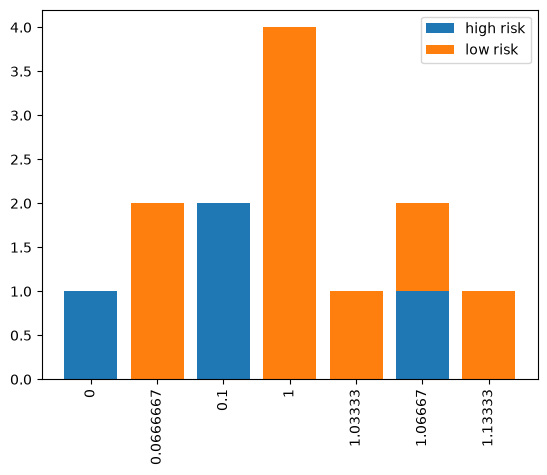

In [12]:
from ctreex.plot import leaf_metric_barplot
from ctreex.counterfactuals import support_set_metric

matrix, leaf_ids, leaf_classes = explainer.leaf_distance_matrix()
leaf = explanation.leaf
leaf_metric_barplot(leaf, matrix, leaf_ids, leaf_classes);

In [13]:
for bin_, leaves in support_set_metric(leaf, matrix, leaf_ids, leaf_classes, bins_step=0.5).items():
    if leaves['same'] or leaves['other']:
        print(bin_, leaves)

(-0.0001, 0.5] {'same': [6, 12, 13], 'other': [4, 5]}
(0.5, 1.0] {'same': [], 'other': [16, 17, 23, 24]}
(1.0, 1.5] {'same': [10], 'other': [9, 20, 21]}


## 6. scikit-learn helpers

Text, Graphviz (DOT) and matplotlib representations of the tree, feature importance and the path from the root to a leaf.

In [14]:
from ctreex import sklearn_tools

class_map = {'good': 'low risk', 'bad': 'high risk'}
print(sklearn_tools.decision_tree_text(clf, spec.column_names, class_map=class_map, max_depth=2))

|--- checking_account=A14 <= 0.50
|   |--- duration <= 22.50
|   |   |--- property=A124 <= 0.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- property=A124 >  0.50
|   |   |   |--- class: high risk
|   |--- duration >  22.50
|   |   |--- savings=A61 <= 0.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- savings=A61 >  0.50
|   |   |   |--- truncated branch of depth 2
|--- checking_account=A14 >  0.50
|   |--- other_installment_plans=A143 <= 0.50
|   |   |--- credit_amount <= 2198.00
|   |   |   |--- class: low risk
|   |   |--- credit_amount >  2198.00
|   |   |   |--- class: low risk
|   |--- other_installment_plans=A143 >  0.50
|   |   |--- age <= 30.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- age >  30.50
|   |   |   |--- truncated branch of depth 2



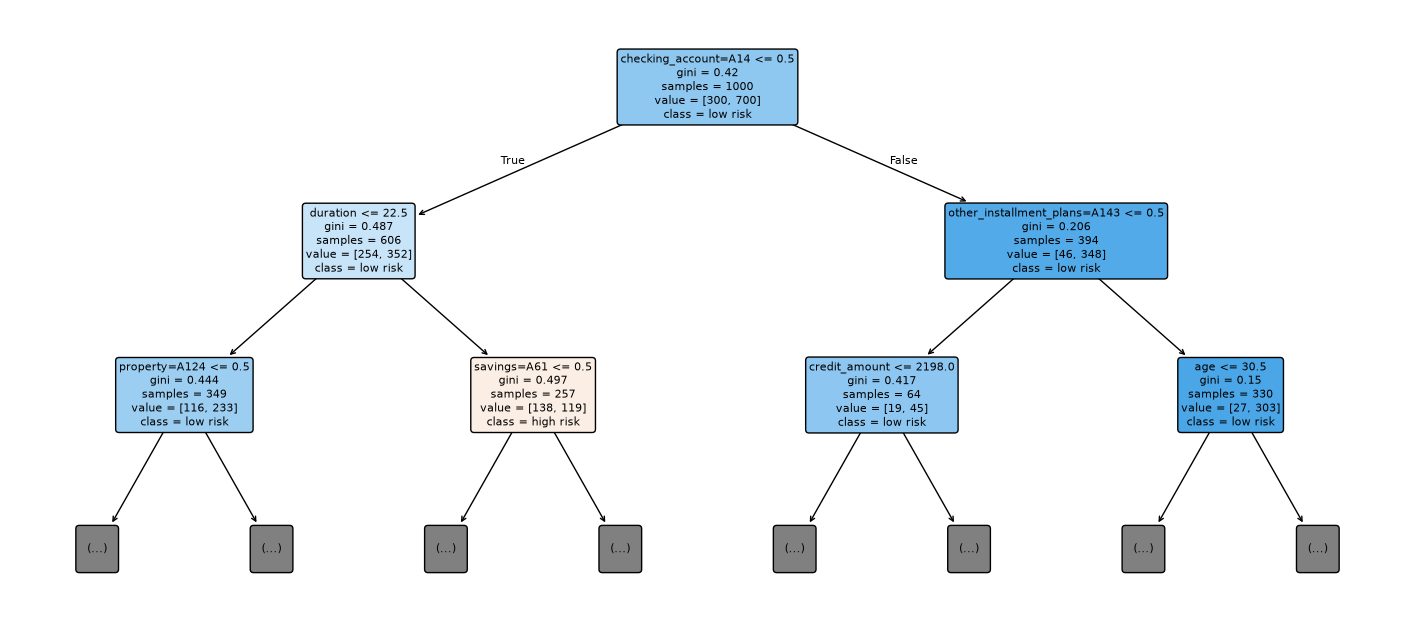

In [15]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(18, 8))
sklearn_tools.decision_tree_plot(clf, spec.column_names, class_map=class_map, max_depth=2, ax=ax, fontsize=8);

In [16]:
importance = sklearn_tools.decision_tree_feature_importance(clf)
for j in np.argsort(importance)[::-1][:5]:
    print('{:35s} {:.3f}'.format(spec.column_names[j], importance[j]))

checking_account=A14                0.467
duration                            0.274
savings=A61                         0.070
other_installment_plans=A143        0.053
credit_history=A32                  0.047


In [17]:
path = sklearn_tools.decision_tree_root2leaf(clf, leaf)
print('nodes from the root to leaf', leaf, ':', path.tolist())
for node, child in zip(path[:-1], path[1:]):
    column = spec.column_names[clf.tree_.feature[node]]
    side = '<=' if clf.tree_.children_left[node] == child else '>'
    print('  {} {} {:.1f}'.format(column, side, clf.tree_.threshold[node]))

nodes from the root to leaf 13 : [0, 1, 7, 11, 13]
  checking_account=A14 <= 0.5
  duration > 22.5
  savings=A61 > 0.5
  duration > 43.5


In [18]:
dot = sklearn_tools.decision_tree_dot(clf, spec.column_names, class_names=['high risk', 'low risk'])
print(dot[:300], '...')

digraph Tree {
node [shape=box, style="filled, rounded", color="black", fontname="helvetica"] ;
edge [fontname="helvetica"] ;
0 [label=<checking_account=A14 &le; 0.5<br/>gini = 0.42<br/>samples = 1000<br/>value = [300, 700]<br/>class = low risk>, fillcolor="#8ec7f0"] ;
1 [label=<duration &le; 22.5<b ...


`graphviz_tree` renders the tree with the `graphviz` package, which also needs the Graphviz programs:

In [19]:
import shutil
try:
    import graphviz  # noqa: F401
    available = shutil.which('dot') is not None
except ImportError:
    available = False
if available:
    display(sklearn_tools.graphviz_tree(clf, spec.column_names, class_map=class_map))
else:
    print('Install graphviz (pip) and Graphviz (https://graphviz.org) to render the tree.')

Install graphviz (pip) and Graphviz (https://graphviz.org) to render the tree.
